<a href="https://colab.research.google.com/github/Janeferdinant/Machine-learning-Course/blob/master/CNN_Identify_the_Digits_%28MNIST%29_validation_split.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CNN on MNIST with a separate validation split

This is a companion to `CNN_Identify_the_Digits_(MNIST).ipynb`, which is left unchanged. That notebook passes the **test** images to `model.fit` as `validation_data`. Here the network, optimiser, batch size (10) and number of epochs (5) are the same, but:

* the last 10,000 of the 60,000 **training** images are held out as the validation set, and the network trains on the first 50,000;
* the 10,000 test images are not touched until the very end, and they are evaluated **once**;
* the random seeds are fixed (see the next cell).

This notebook is a single-seed demonstration (seed 0). Three seeds, timings, the comparison with the original 0.9905 and what the split does and does not change are in `docs/runs/2026-10-14-mnist-validation-split.md`; the script that produced the three-seed numbers is `scripts/mnist_validation_split.py`.

## Setup and seeds

In [1]:
# Packages: see requirements.txt (tensorflow, keras, numpy, matplotlib, scikit-learn). On Colab they are already installed.
import os, random, time
import numpy as np
import tensorflow as tf
import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D
from keras.datasets import mnist
import matplotlib.pyplot as plt

SEED = 0
random.seed(SEED)                  # python
np.random.seed(SEED)               # numpy
tf.random.set_seed(SEED)           # TensorFlow
keras.utils.set_random_seed(SEED)  # sets all three again (python, numpy, TensorFlow)
print("seed =", SEED, "| TensorFlow", tf.__version__, "| Keras", keras.__version__)

seed = 0 | TensorFlow 2.15.1 | Keras 2.15.0


## Data: train, validation and test

In [2]:
(x_all, y_all), (x_test, y_test) = mnist.load_data()
print(x_all.shape, y_all.shape)
print(x_test.shape, y_test.shape)

(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)


In [3]:
# CNN input: 28 x 28 x 1, pixels scaled to 0..1, labels one-hot encoded
x_all = x_all.reshape(-1, 28, 28, 1).astype("float32") / 255
x_test = x_test.reshape(-1, 28, 28, 1).astype("float32") / 255
y_all_cat = tf.keras.utils.to_categorical(y_all, num_classes=10)
y_test_cat = tf.keras.utils.to_categorical(y_test, num_classes=10)
input_shape = (28, 28, 1)

# Validation split from the TRAINING data only: the last 10,000 of the 60,000 training images.
N_VAL = 10_000
x_train, y_train = x_all[:-N_VAL], y_all_cat[:-N_VAL]
x_val, y_val = x_all[-N_VAL:], y_all_cat[-N_VAL:]
print("train     :", x_train.shape[0], "images")
print("validation:", x_val.shape[0], "images (held out from training data)")
print("test      :", x_test.shape[0], "images (not used until the final cell)")
print("validation label counts:", np.bincount(y_all[-N_VAL:]))

train     : 50000 images
validation: 10000 images (held out from training data)
test      : 10000 images (not used until the final cell)
validation label counts: [ 991 1064  990 1030  983  915  967 1090 1009  961]


## Model (same architecture, optimiser, batch size and epochs as the original notebook)

In [4]:
num_classes = 10

model = Sequential()
model.add(Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=input_shape))
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))
model.add(Flatten())
model.add(Dense(256, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(num_classes, activation='softmax'))

model.compile(loss=keras.losses.categorical_crossentropy, optimizer='adam', metrics=['accuracy'])
model.summary()

Model: "sequential"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 conv2d (Conv2D)             (None, 26, 26, 32)        320       


 conv2d_1 (Conv2D)           (None, 24, 24, 64)        18496     


...

 dense_1 (Dense)             (None, 10)                2570      


Total params: 2380938 (9.08 MB)


Trainable params: 2380938 (9.08 MB)


Non-trainable params: 0 (0.00 Byte)


_________________________________________________________________


## Training (validation data = held-out training images)

In [5]:
t0 = time.time()
hist = model.fit(x_train, y_train, epochs=5, batch_size=10, verbose=2,
                 validation_data=(x_val, y_val))
print("The model has successfully trained in %.0f s" % (time.time() - t0))

Epoch 1/5


5000/5000 - 65s - loss: 0.1609 - accuracy: 0.9510 - val_loss: 0.0487 - val_accuracy: 0.9863 - 65s/epoch - 13ms/step


Epoch 2/5


5000/5000 - 63s - loss: 0.0733 - accuracy: 0.9777 - val_loss: 0.0430 - val_accuracy: 0.9878 - 63s/epoch - 13ms/step


Epoch 3/5


...

Epoch 4/5


5000/5000 - 63s - loss: 0.0445 - accuracy: 0.9860 - val_loss: 0.0391 - val_accuracy: 0.9898 - 63s/epoch - 13ms/step


Epoch 5/5


5000/5000 - 63s - loss: 0.0362 - accuracy: 0.9889 - val_loss: 0.0363 - val_accuracy: 0.9901 - 63s/epoch - 13ms/step


The model has successfully trained in 318 s


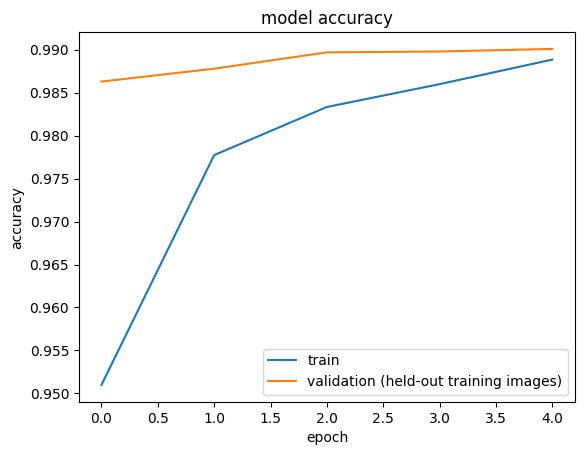

In [6]:
plt.plot(hist.history['accuracy'])
plt.plot(hist.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'validation (held-out training images)'], loc='lower right')
plt.show()

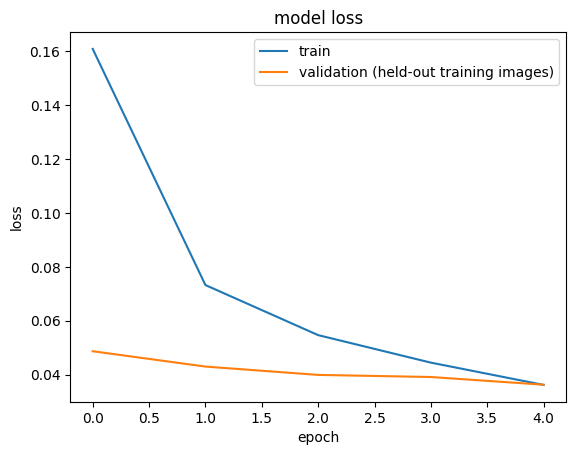

In [7]:
plt.plot(hist.history['loss'])
plt.plot(hist.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation (held-out training images)'], loc='upper right')
plt.show()

## Final test evaluation (done once)

The test set is used for the first time here. One prediction pass gives the loss, the accuracy and the report below; nothing was tuned, selected or stopped using the test set.

In [8]:
probs = model.predict(x_test, verbose=0)               # the only pass over the test set
y_pred = np.argmax(probs, axis=1)
test_loss = float(np.mean(keras.losses.categorical_crossentropy(y_test_cat, probs)))
test_acc = float(np.mean(y_pred == y_test))
print('Test loss:', test_loss)
print('Test accuracy:', test_acc)
print('correct:', int(np.sum(y_pred == y_test)), '| wrong:', int(np.sum(y_pred != y_test)))

Test loss: 0.031851209700107574
Test accuracy: 0.9907
correct: 9907 | wrong: 93


In [9]:
from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.99      0.99      0.99      1032
           3       1.00      0.99      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.99      1.00      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      0.98      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.98      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000

[[ 971    1    1    0    0    0    4    1    1    1]
 [   0 1132    1    0    0    2    0    0    0    0]
 [   1    2 1023    0    1    0    0    5    0    0]
 [   0    0    3 1003    0    3    0    0    1    0]
 [   0    0    0    0  970   

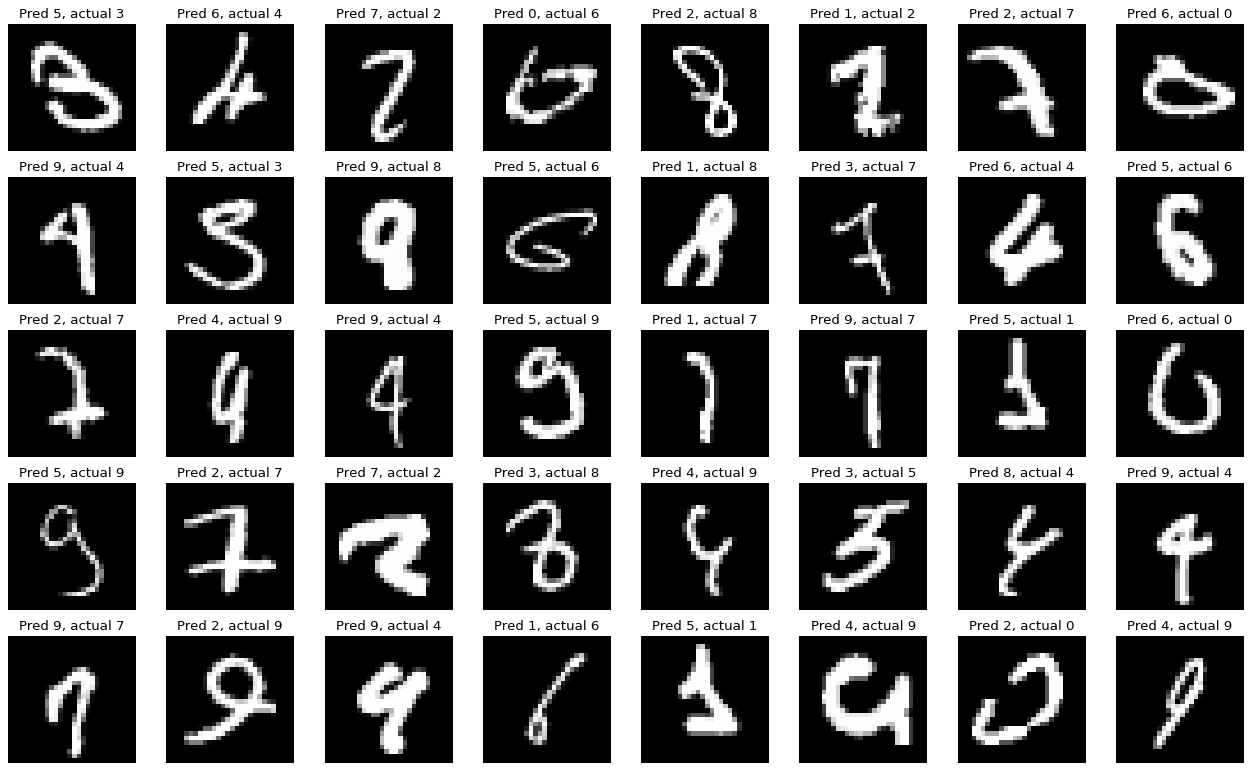

In [10]:
incorrect_indices = list(np.where(y_pred != y_test)[0])
plt.figure(figsize=(20, 12), dpi=80, facecolor='w', edgecolor='k')
for i, idx in enumerate(incorrect_indices[:40]):
    plt.subplot(5, 8, i + 1)
    plt.imshow(x_test[idx].reshape(28, 28), cmap='gray', interpolation='none')
    plt.title("Pred {}, actual {}".format(y_pred[idx], y_test[idx]))
    plt.axis('off')
plt.show()